# Step 02: Bigram language model

Tests for `02-bigram/bigram.py`. Write code in the `.py` file, only import and test here.

Run the cells top to bottom (Run All).

In [1]:
%load_ext autoreload
%autoreload 2

import math
import sys
import torch
import matplotlib.pyplot as plt

sys.path.append("02-bigram")
from bigram import (
    VOCAB_SIZE, get_device, load_data, split_data, decode,
    get_batch, BigramLanguageModel, train,
)

device = get_device()
print("device:", device)

device: mps


## 1. Data

Text becomes a 1-D tensor of byte values (0-255). Provided helpers, nothing to write.

In [2]:
data = load_data("02-bigram/data/input.txt")
train_data, val_data = split_data(data)

print(data.shape, data.dtype)       # (1115394,) torch.int64
print(data[:10])                    # first 10 byte values
print(decode(data[:10]))            # 'First Citi'
print(len(train_data), len(val_data))

torch.Size([1115394]) torch.int64
tensor([ 70, 105, 114, 115, 116,  32,  67, 105, 116, 105])
First Citi
1003854 111540


## 2. `get_batch`

Random chunks of text. `y` is `x` shifted one token right: the model learns to predict the next token at every position.

In [3]:
torch.manual_seed(0)
x, y = get_batch(train_data, block_size=8, batch_size=4)

print(x.shape, y.shape)            # expect (4, 8) and (4, 8)
print(x[0])
print(y[0])                        # should be x[0] shifted left by one
assert (x[:, 1:] == y[:, :-1]).all(), "y must be x shifted by one"
print(repr(decode(x[0])), "->", repr(decode(y[0])))

torch.Size([4, 8]) torch.Size([4, 8])
tensor([104, 101,  32, 103, 105, 118, 101, 115])
tensor([101,  32, 103, 105, 118, 101, 115,  32])
'he gives' -> 'e gives '


## 3. Model and loss

One `nn.Embedding(256, 256)` is the whole model. Untrained, it guesses almost at random, so the loss should be near `ln(256) = 5.55` (a bit higher because the random table is not perfectly uniform).

In [4]:
model = BigramLanguageModel(VOCAB_SIZE).to(device)
x, y = get_batch(train_data, block_size=8, batch_size=4, device=device)

logits, loss = model(x, y)
print(logits.shape)                # expect (4, 8, 256)
print(loss.item())                 # expect around 5.5 to 6.2
print("uniform guess:", math.log(256))

logits, loss = model(x)            # no targets
print(loss)                        # expect None

torch.Size([4, 8, 256])
5.889766693115234
uniform guess: 5.545177444479562
None


## 4. `generate` before training

Same loop that every LLM uses: predict, sample, append, repeat. Untrained, the output is random bytes.

In [5]:
start = torch.zeros((1, 1), dtype=torch.long, device=device)  # seed with token 0
out = model.generate(start, max_new_tokens=100)
print(out.shape)                   # expect (1, 101)
print(repr(decode(out[0].tolist())))   # gibberish

torch.Size([1, 101])
"\x00�Hy�\x10\x1d�Br��\x08´�=l����@�\x16p��}����\x1e��\t�pFRlC��u�����\x07'\x0e\x15\x0c�|\x03��Q;q,H�\x1d\x01�����\\�)�Ad`���^%�\x12��p�#[�(�\\"


## 5. Train

AdamW on random batches. The loss should fall from ~5.5 to about 2.5.

first 100 steps avg: 5.384
last 100 steps avg:  2.473


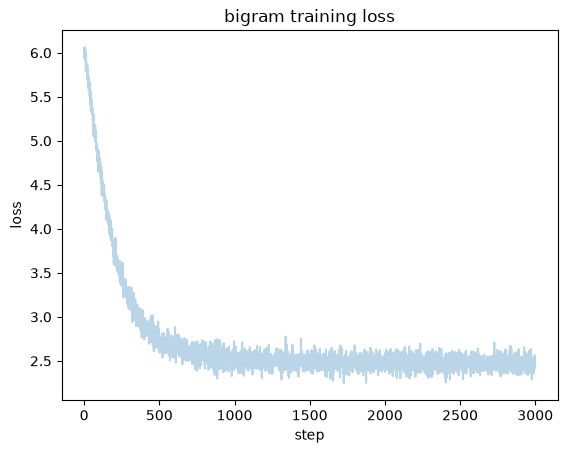

In [6]:
torch.manual_seed(0)
model = BigramLanguageModel(VOCAB_SIZE).to(device)
losses = train(model, train_data, steps=3000, batch_size=32, block_size=8,
               lr=1e-2, device=device)

print(f"first 100 steps avg: {sum(losses[:100]) / 100:.3f}")
print(f"last 100 steps avg:  {sum(losses[-100:]) / 100:.3f}")   # expect roughly 2.5

plt.plot(losses, alpha=0.3)
plt.xlabel("step"); plt.ylabel("loss"); plt.title("bigram training loss")
plt.show()

## 6. Validation loss

Loss on text the model never trained on. It should be close to the training loss, since a bigram table is too small to memorize.

In [7]:
@torch.no_grad()
def eval_loss(model, data, n_batches=50):
    total = 0.0
    for _ in range(n_batches):
        x, y = get_batch(data, block_size=8, batch_size=32, device=device)
        _, loss = model(x, y)
        total += loss.item()
    return total / n_batches

print("train:", round(eval_loss(model, train_data), 3))
print("val:  ", round(eval_loss(model, val_data), 3))

train: 2.486
val:   2.492


## 7. `generate` after training

Expect text-shaped output: line breaks, capital letters after newlines, short word-like pieces. Not real words, because each byte only sees the one before it.

In [8]:
out = model.generate(start, max_new_tokens=400)
print(decode(out[0].tolist()))

 MPe h hirdatese hist misprut us,



K�prcld��ulis d 'd wa t chifrt, anom. mp, my b`����?
Sorpremel du trndsoy s, ashons ce he a ha��]?
Whabeng STyicearellon.
T������harce�doopood,
The ie itep hirwen ry w hischt
Thee ir ndef hoths; h's chadr y woudrouponus brs by, y t mmee, the h s
t, edo therd s IONThe terono; vis he yes ��barom
I ir d sthere alit te st mel, rin, tinonjo be Cin; mumoriothede a


## Why the bigram is limited

Each prediction uses only the previous token, so `th` can lead to `e`, but the model cannot know what came three tokens ago. Fixing that means letting tokens look at earlier tokens: **self-attention**, step 03.